# Paso 1 · ¿Qué mide realmente `percent_bleaching`?

**Objetivo:** antes de mejorar el modelo, entender si la variable objetivo significa lo mismo en todas las filas.

**Hipótesis:** `bleaching_level` (Colony / Population) no describe el arrecife, sino *cómo y quién* hizo el muestreo. En los datos originales solo existían `Population` y `nd` (no documentado); la categoría `Colony` se creó en la limpieza al rellenar los `nd`. La columna que lo explica es `Data_Source`, que se descartó en la limpieza.

In [1]:
import kagglehub, pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt

path = kagglehub.dataset_download("mehrdat/coral-reef-global-bleaching")
raw = pd.read_csv(f"{path}/coral.csv", low_memory=False).replace("nd", np.nan)
for c in ["Percent_Bleaching", "TSA_DHW", "SSTA_DHW"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
raw["level"] = raw["Bleaching_Level"].fillna("nd")
raw.shape

/Users/veronica/Desktop/Bootcamp/finalproject/corals/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(41361, 63)

## 1. ¿Quién registró cada nivel?
Fíjate en que `Population` viene **solo** de Reef Check. Todo lo que acabó siendo "Colony" viene de otras fuentes.

In [2]:
pd.crosstab(raw["Data_Source"], raw["level"])

level,Population,nd
Data_Source,,
AGRRA,0,2848
Donner,0,6307
FRRP,0,2394
Kumagai,0,667
McClanahan,0,234
Nuryana,0,5
Reef_Check,22531,6290
Safaie,0,81
Setiawan,0,4


## 2. Cada fuente tiene su propia "escala"
Mira la media, la mediana y el % de ceros. Ojo con **Donner: 0 % de ceros** — es una base de datos que recopila *informes de blanqueamiento*, no muestreos sistemáticos (si no había blanqueamiento, casi nadie lo reportaba).

In [3]:
lab = raw.dropna(subset=["Percent_Bleaching"])
summary = lab.groupby("Data_Source").agg(
    n=("Percent_Bleaching", "size"),
    mean=("Percent_Bleaching", "mean"),
    median=("Percent_Bleaching", "median"),
    pct_zeros=("Percent_Bleaching", lambda s: (s == 0).mean() * 100),
    first_year=("Date_Year", "min"),
    last_year=("Date_Year", "max"),
).round(1).sort_values("n", ascending=False)
summary

,n,mean,median,pct_zeros,first_year,last_year
Data_Source,,,,,,
Reef_Check,22531,2.5,0.0,66.1,1998,2020
Donner,5770,35.0,30.5,0.0,1980,2011
AGRRA,2848,3.3,0.9,41.8,1998,2016
FRRP,2394,15.3,10.3,8.4,2005,2016
Kumagai,660,17.5,5.5,49.8,2004,2016
McClanahan,226,57.3,62.9,0.9,2016,2016
Safaie,77,24.4,5.0,27.3,1997,2011
Nuryana,5,30.9,35.0,0.0,2015,2016
Setiawan,4,66.0,65.5,0.0,2016,2016


## 3. Donner convierte categorías en números
Muchos valores de Donner son el **punto medio de una categoría** ("Moderate 11–50 %" → ~30 %), no una medida.

In [4]:
lab.loc[lab["Data_Source"] == "Donner", "Bleaching_Comments"].value_counts().head(8)

Bleaching_Comments
Bleaching percentage averaged from code: Mild (1-10% Bleached)         1049
Bleaching percent averaged from code: Severe (>50% Bleached)            752
Bleaching percentage averaged from code: Moderate (11-50% Bleached)     481
Name: count, dtype: int64

## 4. La prueba clave: mismo calor, distinto blanqueamiento según la fuente
Si la fuente no importara, cada columna tendría valores parecidos en todas las filas. Con **TSA_DHW = 0** (sin estrés térmico), Donner reporta ~28 % y Reef Check ~2 %. La fuente pesa más que el calor.

Pero **dentro de cada fuente** la relación con el calor sí es clara (sube de izquierda a derecha). Esa es la señal que queremos que aprenda el modelo.

In [5]:
lab = lab.dropna(subset=["TSA_DHW"]).copy()
lab["dhw_bin"] = pd.cut(lab["TSA_DHW"], [-0.1, 0, 4, 8, 100], labels=["0", "0–4", "4–8", "8+"])
display(lab.pivot_table(index="Data_Source", columns="dhw_bin", values="Percent_Bleaching", aggfunc="mean", observed=False).round(1))
lab.pivot_table(index="Data_Source", columns="dhw_bin", values="Percent_Bleaching", aggfunc="size", observed=False)

dhw_bin,0,0–4,4–8,8+
Data_Source,,,,
AGRRA,2.8,7.4,1.5,10.1
Donner,28.1,34.7,45.0,55.6
FRRP,9.7,18.8,31.9,22.0
Kumagai,7.9,20.6,40.2,44.6
McClanahan,42.6,59.0,63.4,59.0
Nuryana,41.5,NaN,30.0,27.7
Reef_Check,1.8,3.8,7.1,8.5
Safaie,14.4,22.1,39.8,38.6
Setiawan,NaN,52.0,70.7,NaN


dhw_bin,0,0–4,4–8,8+
Data_Source,,,,
AGRRA,2369,359,118,2
Donner,2741,1497,1103,418
FRRP,1196,921,168,109
Kumagai,369,164,101,26
McClanahan,41,106,67,12
Nuryana,1,0,1,3
Reef_Check,16570,4632,860,359
Safaie,35,14,13,14
Setiawan,0,1,3,0


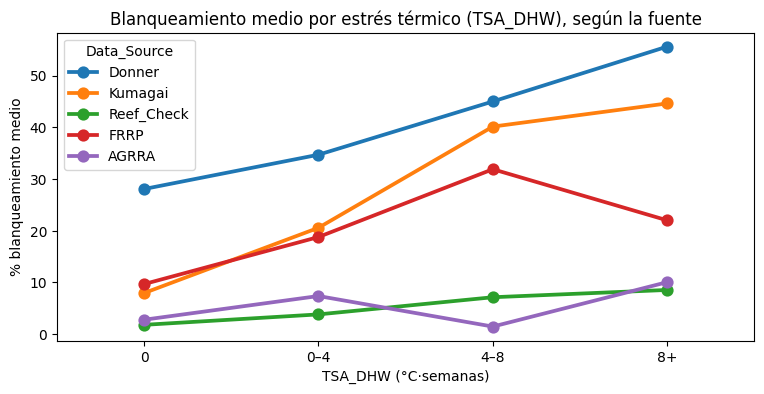

In [6]:
main = lab[lab["Data_Source"].isin(["Reef_Check", "Donner", "AGRRA", "FRRP", "Kumagai"])]
plt.figure(figsize=(9, 4))
sns.pointplot(data=main, x="dhw_bin", y="Percent_Bleaching", hue="Data_Source", errorbar=None)
plt.title("Blanqueamiento medio por estrés térmico (TSA_DHW), según la fuente")
plt.ylabel("% blanqueamiento medio"); plt.xlabel("TSA_DHW (°C·semanas)")
plt.show()

## 5. Decisión

| Opción | Qué entrena | A favor | En contra |
|---|---|---|---|
| **A. Solo Reef Check** | ~22.500 muestreos, 1998–2020, protocolo único | Escala coherente, incluye ceros reales, cobertura global | Valores bajos (mide % de colonias en un transecto amplio); pocos casos extremos (359 con DHW 8+) |
| **B. Muestreos sistemáticos** (Reef Check + AGRRA + FRRP + Kumagai) con `Data_Source` como variable | ~28.000 | Más datos y más variedad | Hay que elegir una fuente "de referencia" al predecir en la app |
| **C. Todo, con `Data_Source` como variable** | ~32.000 | Incluye Donner (eventos históricos 1980–2011) | Donner no tiene ceros y usa categorías: enseña al modelo que "siempre hay blanqueamiento" |

**Recomendación:** empezar con **A** como modelo base limpio y probar **B** como comparación. Dejar Donner fuera del entrenamiento (puede seguir en la app como contexto histórico).

**Consecuencia para la app:** las cifras pasarán a significar *"% de corales blanqueados en un muestreo estándar tipo Reef Check"*, y serán más bajas que las actuales.

✍️ **Tu decisión:**

_(escribe aquí A, B o C y por qué)_